In [1]:
print("Hii this is TARACHAND")

Hii this is TARACHAND


# AI461 – Advanced Biometric Systems and Security
## Assignment 1: User Authentication using Biometric Features

### Objective

The objective of this assignment is to evaluate the performance of a biometric
authentication system using biometric feature vectors.

The dataset contains biometric feature vectors for 100 users. Each user has
10 samples, where the first 5 samples are used for enrollment/training and
the remaining 5 samples are used for testing.

Each biometric sample is represented by 144 features.

Two matching criteria are evaluated:

1. Euclidean Distance
2. Cosine Similarity

The following biometric performance measures are computed:

- Genuine Distribution
- Impostor Distribution
- False Acceptance Rate (FAR)
- False Rejection Rate (FRR)
- Receiver Operating Characteristic (ROC)
- Equal Error Rate (EER)
- Decidability Index

Finally, Euclidean Distance and Cosine Similarity are compared to determine
which matching criterion provides better authentication performance.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.distance import cdist
from sklearn.metrics import roc_curve, auc

In [4]:
DATA_PATH = "biomet_data.csv"

data = pd.read_csv(DATA_PATH, sep="\t", header=None)

print("Original dataset shape:", data.shape)

Original dataset shape: (144, 1001)


In [5]:
data = data.dropna(axis=1, how="all")

print("Dataset shape after removing empty columns:", data.shape)

Dataset shape after removing empty columns: (144, 1000)


In [6]:
print("Number of features :", data.shape[0])
print("Number of samples  :", data.shape[1])

print("\nFirst 5 features × first 5 samples:")
display(data.iloc[:5, :5])

Number of features : 144
Number of samples  : 1000

First 5 features × first 5 samples:


,0,1,2,3,4
0,307.02177,296.77448,213.03365,195.24468,229.44699
1,364.09315,348.58811,331.81183,289.80958,327.11110
2,239.10673,238.26485,289.61825,173.42357,281.41246
3,206.98782,241.55478,281.39093,219.13554,252.41240
4,192.14200,216.70194,245.03126,216.16553,220.47665


In [7]:
X = data.to_numpy(dtype=np.float64).T

print("Feature matrix shape:", X.shape)

Feature matrix shape: (1000, 144)


In [8]:
NUM_USERS = 100
SAMPLES_PER_USER = 10
TRAIN_SAMPLES = 5
TEST_SAMPLES = 5
NUM_FEATURES = 144

print("Number of users       :", NUM_USERS)
print("Samples per user      :", SAMPLES_PER_USER)
print("Training samples/user :", TRAIN_SAMPLES)
print("Testing samples/user  :", TEST_SAMPLES)
print("Features per sample   :", NUM_FEATURES)

Number of users       : 100
Samples per user      : 10
Training samples/user : 5
Testing samples/user  : 5
Features per sample   : 144


In [9]:
assert X.shape == (
    NUM_USERS * SAMPLES_PER_USER,
    NUM_FEATURES
), "Dataset dimensions do not match the assignment!"

print("✓ Dataset dimensions match the assignment.")

✓ Dataset dimensions match the assignment.


In [10]:
user_data = X.reshape(
    NUM_USERS,
    SAMPLES_PER_USER,
    NUM_FEATURES
)

print("User data shape:", user_data.shape)

User data shape: (100, 10, 144)


In [11]:
enrollment_data = user_data[:, :TRAIN_SAMPLES, :]
test_data = user_data[:, TRAIN_SAMPLES:, :]

print("Enrollment data shape:", enrollment_data.shape)
print("Test data shape      :", test_data.shape)

Enrollment data shape: (100, 5, 144)
Test data shape      : (100, 5, 144)


In [12]:
templates = np.mean(enrollment_data, axis=1)

print("Templates shape:", templates.shape)

Templates shape: (100, 144)


In [13]:
print("========== DATASET SUMMARY ==========")
print(f"Total users              : {NUM_USERS}")
print(f"Samples per user         : {SAMPLES_PER_USER}")
print(f"Enrollment samples/user  : {TRAIN_SAMPLES}")
print(f"Test samples/user        : {TEST_SAMPLES}")
print(f"Features per sample      : {NUM_FEATURES}")
print(f"Total enrollment samples : {NUM_USERS * TRAIN_SAMPLES}")
print(f"Total test samples       : {NUM_USERS * TEST_SAMPLES}")
print(f"Templates                : {templates.shape}")
print("======================================")

========== DATASET SUMMARY ==========
Total users              : 100
Samples per user         : 10
Enrollment samples/user  : 5
Test samples/user        : 5
Features per sample      : 144
Total enrollment samples : 500
Total test samples       : 500
Templates                : (100, 144)


In [14]:
test_samples = test_data.reshape(
    NUM_USERS * TEST_SAMPLES,
    NUM_FEATURES
)

print("Test samples shape:", test_samples.shape)

Test samples shape: (500, 144)


In [15]:
test_labels = np.repeat(
    np.arange(NUM_USERS),
    TEST_SAMPLES
)

print("Test labels shape:", test_labels.shape)
print("First 15 labels:", test_labels[:15])

Test labels shape: (500,)
First 15 labels: [0 0 0 0 0 1 1 1 1 1 2 2 2 2 2]


In [16]:
euclidean_scores = cdist(
    test_samples,
    templates,
    metric="euclidean"
)

print("Euclidean score matrix shape:", euclidean_scores.shape)

Euclidean score matrix shape: (500, 100)


In [17]:
genuine_euclidean = euclidean_scores[
    np.arange(len(test_samples)),
    test_labels
]

print("Number of genuine Euclidean scores:", len(genuine_euclidean))
print("\nFirst 10 genuine scores:")
print(genuine_euclidean[:10])

Number of genuine Euclidean scores: 500

First 10 genuine scores:
[412.48222405 324.22833759 623.8450676  391.70441128 347.93545835
 152.50282783 225.6045987  181.39311761 133.78591425 159.54844627]


In [18]:
impostor_mask = np.ones_like(
    euclidean_scores,
    dtype=bool
)

impostor_mask[
    np.arange(len(test_samples)),
    test_labels
] = False

impostor_euclidean = euclidean_scores[
    impostor_mask
]

print("Number of impostor Euclidean scores:",
      len(impostor_euclidean))

Number of impostor Euclidean scores: 49500


In [19]:
print("========== EUCLIDEAN COMPARISONS ==========")
print("Genuine comparisons :", len(genuine_euclidean))
print("Impostor comparisons:", len(impostor_euclidean))
print("Total comparisons   :", 
      len(genuine_euclidean) + len(impostor_euclidean))
print("============================================")

========== EUCLIDEAN COMPARISONS ==========
Genuine comparisons : 500
Impostor comparisons: 49500
Total comparisons   : 50000


In [20]:
print("Genuine Euclidean:")
print("  Mean :", np.mean(genuine_euclidean))
print("  Std  :", np.std(genuine_euclidean))
print("  Min  :", np.min(genuine_euclidean))
print("  Max  :", np.max(genuine_euclidean))

print("\nImpostor Euclidean:")
print("  Mean :", np.mean(impostor_euclidean))
print("  Std  :", np.std(impostor_euclidean))
print("  Min  :", np.min(impostor_euclidean))
print("  Max  :", np.max(impostor_euclidean))

Genuine Euclidean:
  Mean : 291.6160469527521
  Std  : 135.45973405973285
  Min  : 95.99290670532488
  Max  : 1018.3819520418305

Impostor Euclidean:
  Mean : 703.8227764410127
  Std  : 301.7917993265992
  Min  : 215.25531669991156
  Max  : 2274.138206109002


In [21]:
cosine_distance = cdist(
    test_samples,
    templates,
    metric="cosine"
)

cosine_scores = 1 - cosine_distance

print("Cosine score matrix shape:", cosine_scores.shape)

Cosine score matrix shape: (500, 100)


In [22]:
genuine_cosine = cosine_scores[
    np.arange(len(test_samples)),
    test_labels
]

print("Number of genuine cosine scores:", len(genuine_cosine))

print("\nFirst 10 genuine cosine scores:")
print(genuine_cosine[:10])

Number of genuine cosine scores: 500

First 10 genuine cosine scores:
[0.99121624 0.99617181 0.98391646 0.99219532 0.99375371 0.99683639
 0.99278734 0.9951917  0.99743683 0.9963071 ]


In [23]:
impostor_cosine = cosine_scores[
    impostor_mask
]

print("Number of impostor cosine scores:",
      len(impostor_cosine))

Number of impostor cosine scores: 49500


In [24]:
print("========== COSINE COMPARISONS ==========")
print("Genuine comparisons :", len(genuine_cosine))
print("Impostor comparisons:", len(impostor_cosine))
print("Total comparisons   :", 
      len(genuine_cosine) + len(impostor_cosine))
print("=========================================")

========== COSINE COMPARISONS ==========
Genuine comparisons : 500
Impostor comparisons: 49500
Total comparisons   : 50000


In [25]:
print("Genuine Cosine Similarity:")
print("  Mean :", np.mean(genuine_cosine))
print("  Std  :", np.std(genuine_cosine))
print("  Min  :", np.min(genuine_cosine))
print("  Max  :", np.max(genuine_cosine))

print("\nImpostor Cosine Similarity:")
print("  Mean :", np.mean(impostor_cosine))
print("  Std  :", np.std(impostor_cosine))
print("  Min  :", np.min(impostor_cosine))
print("  Max  :", np.max(impostor_cosine))

Genuine Cosine Similarity:
  Mean : 0.989501168181278
  Std  : 0.010956905492758245
  Min  : 0.8828546749828811
  Max  : 0.9985071948369928

Impostor Cosine Similarity:
  Mean : 0.9603761712110512
  Std  : 0.018366488719033444
  Min  : 0.8200397471674756
  Max  : 0.9912920047240527


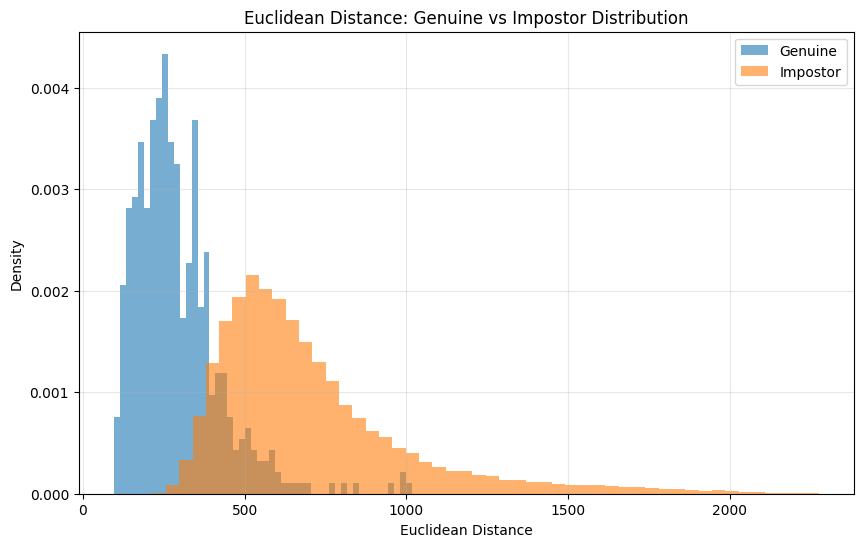

In [26]:
plt.figure(figsize=(10, 6))

plt.hist(
    genuine_euclidean,
    bins=50,
    density=True,
    alpha=0.6,
    label="Genuine"
)

plt.hist(
    impostor_euclidean,
    bins=50,
    density=True,
    alpha=0.6,
    label="Impostor"
)

plt.xlabel("Euclidean Distance")
plt.ylabel("Density")
plt.title("Euclidean Distance: Genuine vs Impostor Distribution")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

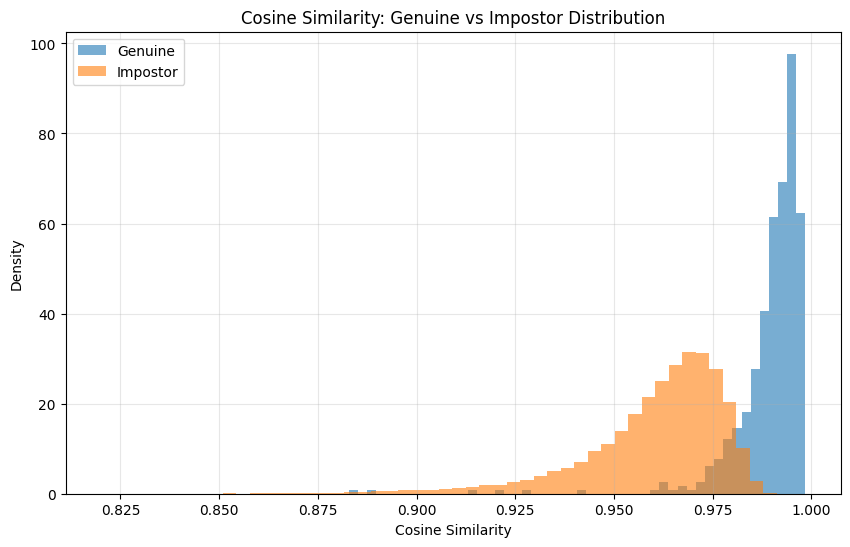

In [27]:
plt.figure(figsize=(10, 6))

plt.hist(
    genuine_cosine,
    bins=50,
    density=True,
    alpha=0.6,
    label="Genuine"
)

plt.hist(
    impostor_cosine,
    bins=50,
    density=True,
    alpha=0.6,
    label="Impostor"
)

plt.xlabel("Cosine Similarity")
plt.ylabel("Density")
plt.title("Cosine Similarity: Genuine vs Impostor Distribution")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [28]:
threshold = 400

# Genuine
genuine_rejected = np.sum(genuine_euclidean > threshold)

# Impostor
impostor_accepted = np.sum(impostor_euclidean <= threshold)

FRR = genuine_rejected / len(genuine_euclidean)
FAR = impostor_accepted / len(impostor_euclidean)

print("Euclidean threshold:", threshold)
print("FAR:", FAR)
print("FRR:", FRR)

Euclidean threshold: 400
FAR: 0.07224242424242425
FRR: 0.15


In [29]:
threshold = 0.98

# Genuine attempts
genuine_rejected = np.sum(genuine_cosine < threshold)

# Impostor attempts
impostor_accepted = np.sum(impostor_cosine >= threshold)

FRR = genuine_rejected / len(genuine_cosine)
FAR = impostor_accepted / len(impostor_cosine)

print("Cosine threshold:", threshold)
print("FAR:", FAR)
print("FRR:", FRR)

Cosine threshold: 0.98
FAR: 0.06272727272727273
FRR: 0.094


In [ ]:
def calculate_far_frr_euclidean(
    genuine_scores,
    impostor_scores,
    threshold
):

    false_rejections = np.sum(genuine_scores > threshold)
    false_acceptances = np.sum(impostor_scores <= threshold)

    frr = false_rejections / len(genuine_scores)
    far = false_acceptances / len(impostor_scores)

    return far, frr

In [31]:
far, frr = calculate_far_frr_euclidean(
    genuine_euclidean,
    impostor_euclidean,
    400
)

print("FAR:", far)
print("FRR:", frr)

FAR: 0.07224242424242425
FRR: 0.15


In [32]:
def calculate_far_frr_cosine(
    genuine_scores,
    impostor_scores,
    threshold
):

    false_rejections = np.sum(genuine_scores < threshold)
    false_acceptances = np.sum(impostor_scores >= threshold)

    frr = false_rejections / len(genuine_scores)
    far = false_acceptances / len(impostor_scores)

    return far, frr

In [33]:
far, frr = calculate_far_frr_cosine(
    genuine_cosine,
    impostor_cosine,
    0.98
)

print("FAR:", far)
print("FRR:", frr)

FAR: 0.06272727272727273
FRR: 0.094


In [34]:
euclidean_thresholds = np.linspace(
    np.min(euclidean_scores),
    np.max(euclidean_scores),
    500
)

euclidean_far = []
euclidean_frr = []

for threshold in euclidean_thresholds:

    far, frr = calculate_far_frr_euclidean(
        genuine_euclidean,
        impostor_euclidean,
        threshold
    )

    euclidean_far.append(far)
    euclidean_frr.append(frr)

euclidean_far = np.array(euclidean_far)
euclidean_frr = np.array(euclidean_frr)

print("Number of thresholds:", len(euclidean_thresholds))

Number of thresholds: 500


In [35]:
cosine_thresholds = np.linspace(
    np.min(cosine_scores),
    np.max(cosine_scores),
    500
)

cosine_far = []
cosine_frr = []

for threshold in cosine_thresholds:

    far, frr = calculate_far_frr_cosine(
        genuine_cosine,
        impostor_cosine,
        threshold
    )

    cosine_far.append(far)
    cosine_frr.append(frr)

cosine_far = np.array(cosine_far)
cosine_frr = np.array(cosine_frr)

print("Number of thresholds:", len(cosine_thresholds))

Number of thresholds: 500


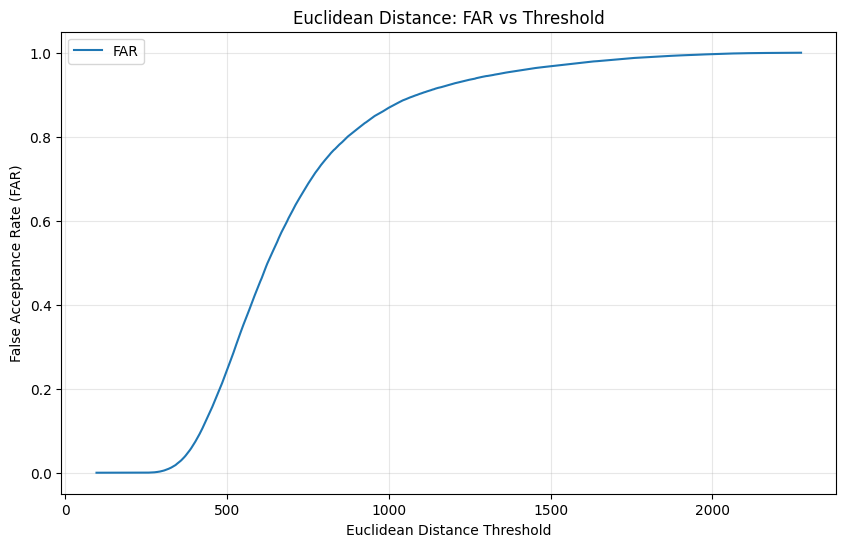

In [36]:
plt.figure(figsize=(10, 6))

plt.plot(
    euclidean_thresholds,
    euclidean_far,
    label="FAR"
)

plt.xlabel("Euclidean Distance Threshold")
plt.ylabel("False Acceptance Rate (FAR)")
plt.title("Euclidean Distance: FAR vs Threshold")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

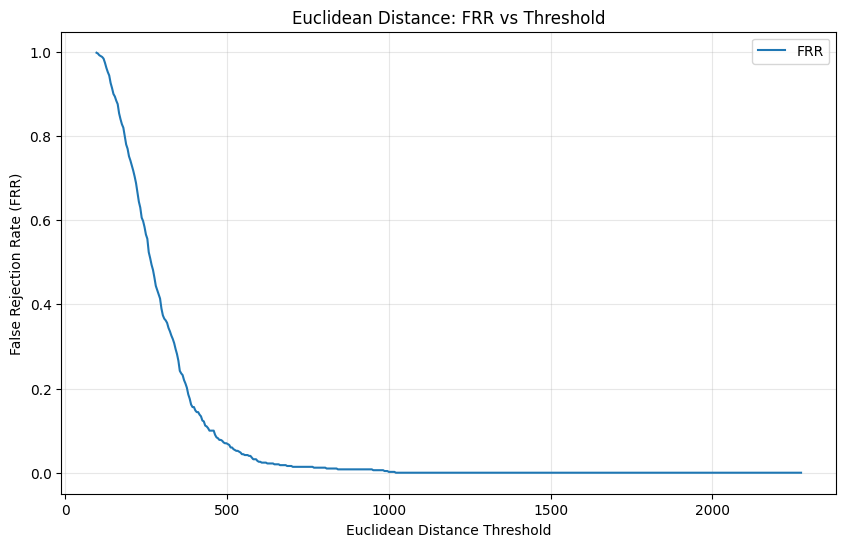

In [37]:
plt.figure(figsize=(10, 6))

plt.plot(
    euclidean_thresholds,
    euclidean_frr,
    label="FRR"
)

plt.xlabel("Euclidean Distance Threshold")
plt.ylabel("False Rejection Rate (FRR)")
plt.title("Euclidean Distance: FRR vs Threshold")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

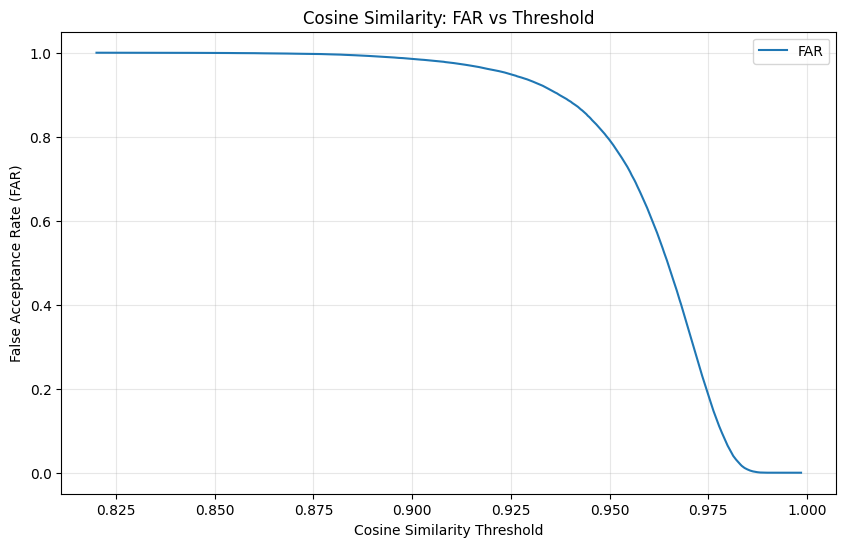

In [38]:
plt.figure(figsize=(10, 6))

plt.plot(
    cosine_thresholds,
    cosine_far,
    label="FAR"
)

plt.xlabel("Cosine Similarity Threshold")
plt.ylabel("False Acceptance Rate (FAR)")
plt.title("Cosine Similarity: FAR vs Threshold")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

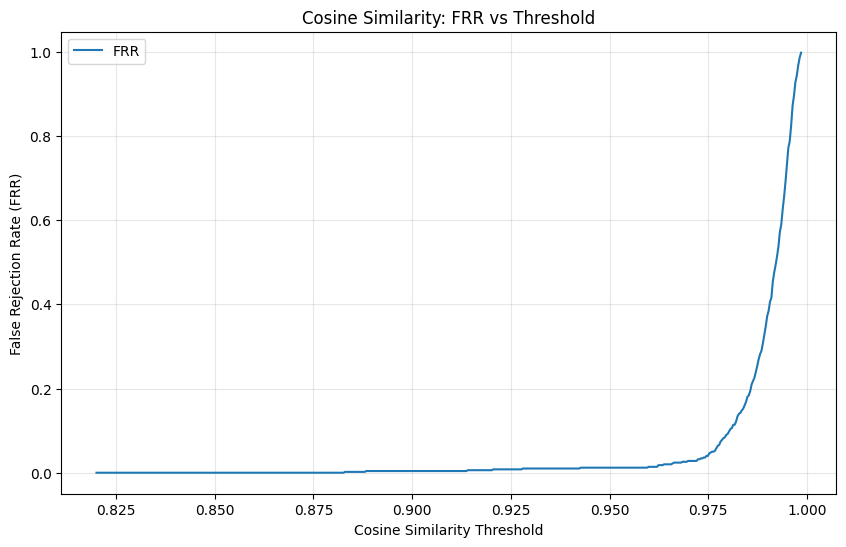

In [39]:
plt.figure(figsize=(10, 6))

plt.plot(
    cosine_thresholds,
    cosine_frr,
    label="FRR"
)

plt.xlabel("Cosine Similarity Threshold")
plt.ylabel("False Rejection Rate (FRR)")
plt.title("Cosine Similarity: FRR vs Threshold")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

In [40]:
y_true = np.concatenate([
    np.ones(len(genuine_euclidean)),
    np.zeros(len(impostor_euclidean))
])

print("Labels shape:", y_true.shape)
print("Genuine labels :", np.sum(y_true == 1))
print("Impostor labels:", np.sum(y_true == 0))

Labels shape: (50000,)
Genuine labels : 500
Impostor labels: 49500


In [41]:
euclidean_roc_scores = np.concatenate([
    -genuine_euclidean,
    -impostor_euclidean
])

print("Euclidean ROC scores:", euclidean_roc_scores.shape)

Euclidean ROC scores: (50000,)


In [42]:
cosine_roc_scores = np.concatenate([
    genuine_cosine,
    impostor_cosine
])

print("Cosine ROC scores:", cosine_roc_scores.shape)

Cosine ROC scores: (50000,)


In [43]:
fpr_euclidean, tpr_euclidean, roc_thresholds_euclidean = roc_curve(
    y_true,
    euclidean_roc_scores
)

auc_euclidean = auc(
    fpr_euclidean,
    tpr_euclidean
)

print("Euclidean ROC points:", len(fpr_euclidean))
print("Euclidean AUC:", auc_euclidean)

Euclidean ROC points: 490
Euclidean AUC: 0.9495562424242423


In [44]:
fpr_cosine, tpr_cosine, roc_thresholds_cosine = roc_curve(
    y_true,
    cosine_roc_scores
)

auc_cosine = auc(
    fpr_cosine,
    tpr_cosine
)

print("Cosine ROC points:", len(fpr_cosine))
print("Cosine AUC:", auc_cosine)

Cosine ROC points: 298
Cosine AUC: 0.9689432323232323


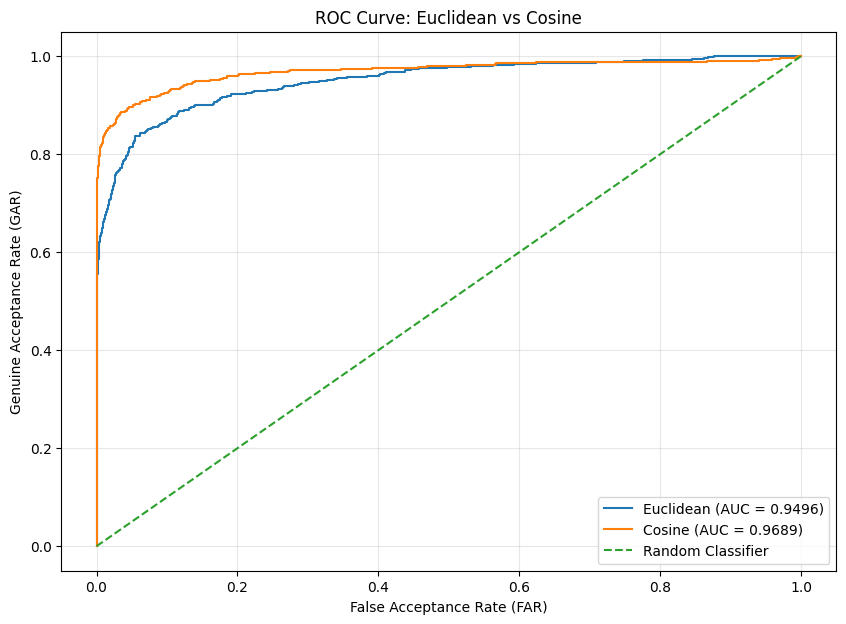

In [45]:
plt.figure(figsize=(10, 7))

plt.plot(
    fpr_euclidean,
    tpr_euclidean,
    label=f"Euclidean (AUC = {auc_euclidean:.4f})"
)

plt.plot(
    fpr_cosine,
    tpr_cosine,
    label=f"Cosine (AUC = {auc_cosine:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Acceptance Rate (FAR)")
plt.ylabel("Genuine Acceptance Rate (GAR)")
plt.title("ROC Curve: Euclidean vs Cosine")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [46]:
eer_index_euclidean = np.argmin(
    np.abs(euclidean_far - euclidean_frr)
)

eer_euclidean = (
    euclidean_far[eer_index_euclidean]
    + euclidean_frr[eer_index_euclidean]
) / 2

eer_threshold_euclidean = (
    euclidean_thresholds[eer_index_euclidean]
)

print("========== EUCLIDEAN EER ==========")
print("EER       :", eer_euclidean)
print("EER (%)   :", eer_euclidean * 100)
print("Threshold :", eer_threshold_euclidean)
print("FAR       :", euclidean_far[eer_index_euclidean])
print("FRR       :", euclidean_frr[eer_index_euclidean])
print("====================================")

========== EUCLIDEAN EER ==========
EER       : 0.11588888888888889
EER (%)   : 11.588888888888889
Threshold : 432.0994959920646
FAR       : 0.11977777777777777
FRR       : 0.112


In [47]:
eer_index_cosine = np.argmin(
    np.abs(cosine_far - cosine_frr)
)

eer_cosine = (
    cosine_far[eer_index_cosine]
    + cosine_frr[eer_index_cosine]
) / 2

eer_threshold_cosine = (
    cosine_thresholds[eer_index_cosine]
)

print("============ COSINE EER ============")
print("EER       :", eer_cosine)
print("EER (%)   :", eer_cosine * 100)
print("Threshold :", eer_threshold_cosine)
print("FAR       :", cosine_far[eer_index_cosine])
print("FRR       :", cosine_frr[eer_index_cosine])
print("=====================================")

============ COSINE EER ============
EER       : 0.08205050505050505
EER (%)   : 8.205050505050506
Threshold : 0.9791940842675461
FAR       : 0.0801010101010101
FRR       : 0.084


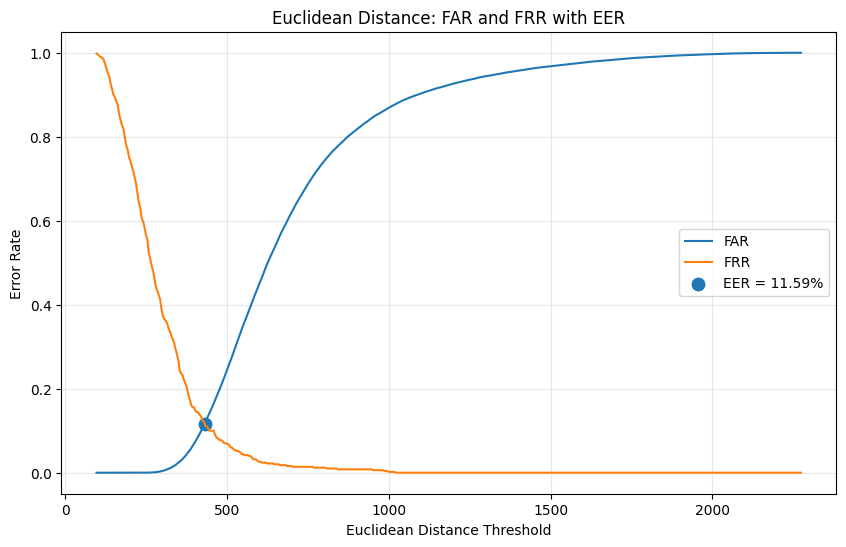

In [48]:
plt.figure(figsize=(10, 6))

plt.plot(
    euclidean_thresholds,
    euclidean_far,
    label="FAR"
)

plt.plot(
    euclidean_thresholds,
    euclidean_frr,
    label="FRR"
)

plt.scatter(
    eer_threshold_euclidean,
    eer_euclidean,
    s=80,
    label=f"EER = {eer_euclidean * 100:.2f}%"
)

plt.xlabel("Euclidean Distance Threshold")
plt.ylabel("Error Rate")
plt.title("Euclidean Distance: FAR and FRR with EER")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

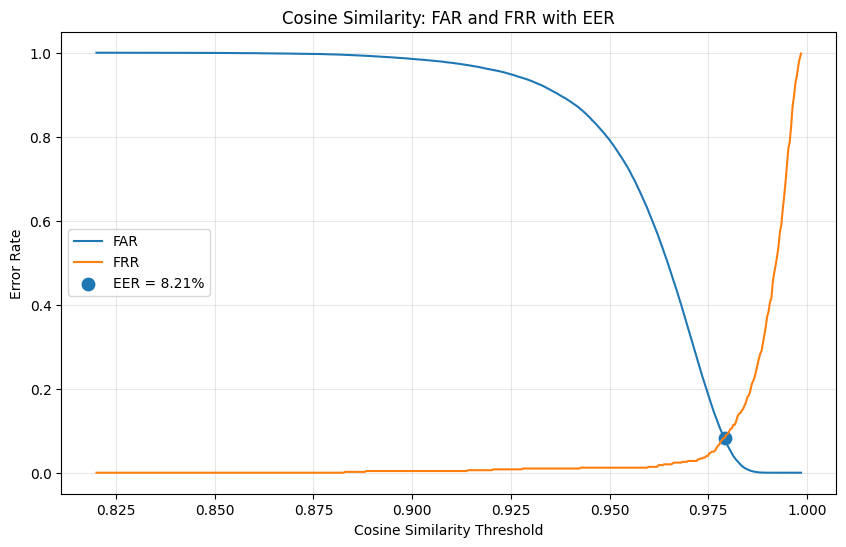

In [49]:
plt.figure(figsize=(10, 6))

plt.plot(
    cosine_thresholds,
    cosine_far,
    label="FAR"
)

plt.plot(
    cosine_thresholds,
    cosine_frr,
    label="FRR"
)

plt.scatter(
    eer_threshold_cosine,
    eer_cosine,
    s=80,
    label=f"EER = {eer_cosine * 100:.2f}%"
)

plt.xlabel("Cosine Similarity Threshold")
plt.ylabel("Error Rate")
plt.title("Cosine Similarity: FAR and FRR with EER")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [50]:
def calculate_decidability_index(
    genuine_scores,
    impostor_scores
):
    genuine_mean = np.mean(genuine_scores)
    impostor_mean = np.mean(impostor_scores)

    genuine_std = np.std(genuine_scores)
    impostor_std = np.std(impostor_scores)

    d_prime = abs(genuine_mean - impostor_mean) / np.sqrt(
        (genuine_std**2 + impostor_std**2) / 2
    )

    return d_prime

In [51]:
d_prime_euclidean = calculate_decidability_index(
    genuine_euclidean,
    impostor_euclidean
)

print("Euclidean Decidability Index (d'):")
print(d_prime_euclidean)

Euclidean Decidability Index (d'):
1.7622461862707726


In [52]:
d_prime_cosine = calculate_decidability_index(
    genuine_cosine,
    impostor_cosine
)

print("Cosine Decidability Index (d'):")
print(d_prime_cosine)

Cosine Decidability Index (d'):
1.92593444819787


In [53]:
comparison = pd.DataFrame({
    "Metric": [
        "AUC",
        "EER (%)",
        "Decidability Index (d')"
    ],
    "Euclidean": [
        auc_euclidean,
        eer_euclidean * 100,
        d_prime_euclidean
    ],
    "Cosine": [
        auc_cosine,
        eer_cosine * 100,
        d_prime_cosine
    ]
})

comparison

,Metric,Euclidean,Cosine
0,AUC,0.949556,0.968943
1,EER (%),11.588889,8.205051
2,Decidability Index (d'),1.762246,1.925934


Conclusion: Both Euclidean Distance and Cosine Similarity are capable of distinguishing genuine and impostor biometric comparisons. However, Cosine Similarity provides better overall performance on the given dataset. It achieves a higher AUC of 0.968943 compared with 0.949556 for Euclidean Distance, a lower EER of 8.21% compared with 11.59%, and a higher Decidability Index of 1.926 compared with 1.762. Therefore, Cosine Similarity is the better matching criterion for this biometric authentication experiment.